# CRC Survival Analysis — SEER Data

**Project:** Colorectal Cancer Survival Analysis  
**Author:** Preston Laney  
**Methods:** Kaplan-Meier estimation, Log-rank test, Cox Proportional Hazards regression  

---

## Overview

This notebook builds a survival analysis pipeline for colorectal cancer using SEER data.  
Phase 1 uses the `lifelines` built-in colon dataset to validate the full pipeline end-to-end.  
Phase 2 swaps in real SEER CRC flat files once the DUA is approved.

### Survival Analysis 101

Survival analysis answers the question: **"How long until an event occurs?"**  
In oncology, the event is usually death (overall survival) or recurrence (disease-free survival).

The challenge that makes this different from ordinary statistics:  
**Censoring** — some patients are still alive at the end of follow-up. We know they survived *at least* that long, but not how long they'll ultimately live. Throwing them out biases the estimate; treating them as deaths is wrong. Survival methods handle this correctly.

**Key methods used here:**

| Method | What it answers |
|--------|-----------------|
| **Kaplan-Meier** | Non-parametric survival curve — no assumptions about distribution |
| **Log-rank test** | Is the difference between two KM curves statistically significant? |
| **Cox PH regression** | What is each variable's independent effect on survival, controlling for others? |

---

## Phase 1 Data Note

The `lifelines` package ships with the classic **Veterans' Administration Lung Cancer dataset** and  
a **colon cancer dataset** from the NCCTG trial (NEJM 1990). We use the colon dataset here.

**Key columns:**
- `time` — days from registration to death or last follow-up
- `status` — 1 = died, 0 = censored (still alive at last contact)
- `rx` — treatment arm: Obs (observation), Lev (levamisole), Lev+5FU
- `age` — age at diagnosis
- `sex` — 1 = male, 0 = female
- `obstruct` — bowel obstruction at presentation (1 = yes)
- `nodes` — number of positive lymph nodes
- `differ` — tumor differentiation (1=well, 2=moderate, 3=poor)
- `extent` — local tumor extent (1=submucosa → 4=contiguous structures)
- `etype` — event type: 1 = recurrence, 2 = death (filter to etype==2 for OS)


---
## 1. Setup & Imports

In [1]:
# Core data tools
# pandas: the primary data manipulation library. Gives us DataFrames and methods like
# .read_csv(), .groupby(), .rename(), boolean indexing, and vectorized column math.
# numpy: numerical operations used for array math and working with NaN values.
import pandas as pd
import numpy as np

# Visualization
# matplotlib is the base plotting engine that almost every Python plot library builds on top of.
# pyplot (plt) is the main interface for creating figures and axes.
# mticker gives us formatters like PercentFormatter to control how axis tick labels display.
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# seaborn is built on top of matplotlib and adds nicer default styles and color palettes.
import seaborn as sns

# Survival analysis
# lifelines is the standard Python survival analysis library.
# KaplanMeierFitter: estimates and plots the non-parametric survival function.
# CoxPHFitter: fits a Cox proportional hazards regression model.
# logrank_test: pairwise significance test comparing two survival curves.
# multivariate_logrank_test: tests whether 3+ survival curves differ simultaneously.
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test, multivariate_logrank_test

# Plot styling applied once here so every plot in the notebook inherits these defaults.
# rcParams is matplotlib's global settings dictionary. .update() merges our settings into it.
# figure.dpi: dots per inch, controls render sharpness in the notebook.
# font.family: sans-serif fonts like Arial are easier to read on screen than serif fonts.
# axes.spines top/right: removes the top and right border lines for a cleaner look.
plt.rcParams.update({
    'figure.dpi': 120,
    'font.family': 'sans-serif',
    'axes.spines.top': False,
    'axes.spines.right': False,
})

# colorblind palette uses blues, oranges, and greens instead of red/green pairs,
# which remain distinguishable for the ~8% of men with red-green color vision deficiency.
sns.set_palette('colorblind')

print('Libraries loaded.')


Libraries loaded.


---
## 2. Load Data

Phase 1 uses the NCCTG colon cancer trial dataset bundled with `lifelines`.  
When real SEER data is available, replace the cell below with your SEER loader.

In [2]:
# load_rossi is not used here. This import just verifies lifelines installed correctly.
from lifelines.datasets import load_rossi

# The colon dataset lives on a public GitHub mirror of R's statistical datasets.
# pd.read_csv() accepts a URL directly. It detects the https:// prefix and makes
# the HTTP request for you, so no manual downloading is needed.
url = "https://vincentarelbundock.github.io/Rdatasets/csv/survival/colon.csv"

# index_col=0 tells pandas to use the first column as the row index rather than
# importing it as a data column. Without this you get a redundant unnamed integer column.
raw = pd.read_csv(url, index_col=0)

# raw.shape returns a (rows, columns) tuple. There are 1,858 rows because each of the
# 929 patients has two rows: one for recurrence (etype 1) and one for death (etype 2).
print(f"Raw shape: {raw.shape}")

# .head() displays the first 5 rows as a formatted table. In Jupyter, the last expression
# in a cell renders automatically as an HTML table without needing print().
raw.head()


Raw shape: (1858, 16)


,id,study,rx,sex,age,obstruct,perfor,adhere,nodes,status,differ,extent,surg,node4,time,etype
rownames,,,,,,,,,,,,,,,,
1,1,1,Lev+5FU,1,43,0,0,0,5.0,1,2.0,3,0,1,1521,2
2,1,1,Lev+5FU,1,43,0,0,0,5.0,1,2.0,3,0,1,968,1
3,2,1,Lev+5FU,1,63,0,0,0,1.0,0,2.0,3,0,0,3087,2
4,2,1,Lev+5FU,1,63,0,0,0,1.0,0,2.0,3,0,0,3087,1
5,3,1,Obs,0,71,0,0,1,7.0,1,2.0,2,0,1,963,2


In [ ]:
# Save raw data to SQLite so we can run SQL queries against it in future notebooks.
# This follows the same pattern as the CMS project.
# We save the full raw table (both etype 1 and etype 2 rows) so nothing is discarded here.
import sqlite3
import os

DB_PATH = r"C:/Users/palla/OneDrive/Documents/Coding Projects/SEER/database/seer.db"

# os.makedirs creates the directory if it does not exist.
# exist_ok=True means it will not raise an error if the folder is already there.
os.makedirs(os.path.dirname(DB_PATH), exist_ok=True)

# sqlite3.connect opens or creates the database file.
# Using it as a context manager (the with statement) ensures the connection closes cleanly.
# .to_sql() writes the DataFrame as a SQL table named 'colon_raw'.
# if_exists='replace' drops and recreates the table on each run so it stays current.
with sqlite3.connect(DB_PATH) as conn:
    raw.to_sql("colon_raw", conn, if_exists="replace", index=True)

print(f"Database: {DB_PATH}")
print(f"Rows saved: {len(raw):,}")
print(f"\nColumn overview:")
for col in raw.columns:
    example = raw[col].dropna().iloc[0]
    print(f"  {col:12s}  dtype={str(raw[col].dtype):8s}  example: {example}")


The raw dataset has two rows per patient because the trial tracked two separate endpoints: recurrence (etype 1, did the cancer come back?) and death (etype 2, did the patient die?). These are different clinical questions and cannot be mixed in one survival curve.

What we are building here is Overall Survival (OS), which is strictly time to death, so we discard the recurrence rows. If both row types were left in, we would have 1,858 observations instead of 929, every patient would appear twice, and the curve would be wrong because the observations are not independent.

The recurrence rows are not lost though. They remain in raw. If you later wanted a disease-free survival curve, you would filter to etype 1 and run the same pipeline on that.

In [3]:
# Filter to Overall Survival endpoint only
# Each patient has two rows in raw: one for recurrence (etype 1) and one for death (etype 2).
# Keeping both would double-count every patient and break the survival math.
# We want OS (time to death), so we keep only etype 2 and drop the recurrence rows.
# .copy() makes this an independent DataFrame so edits here do not affect raw.
os_df = raw[raw['etype'] == 2].copy()

# Time is in days in the raw data. Dividing by 365.25 converts to years (the .25 accounts for leap years).
# Years are far more readable on a survival curve x-axis than days.
os_df['time_years'] = os_df['time'] / 365.25

# Rename cryptic R column names to plain English for readability in all downstream code.
# status -> event: 1 = patient died, 0 = censored (alive at last contact)
# rx -> treatment: the treatment arm label (Obs, Lev, or Lev+5FU)
os_df = os_df.rename(columns={
    'status': 'event',
    'rx':     'treatment',
})

# Sanity checks: confirm row count, event rate, follow-up length, and arm sizes before any analysis.

# len(os_df) counts rows. The :, format spec adds a thousands separator (e.g. 1,858).
print(f"OS cohort: {len(os_df):,} patients")

# .sum() on a 0/1 column counts the 1s (deaths). .mean() gives the proportion, times 100 = percentage.
print(f"Events (deaths): {os_df['event'].sum():,} ({os_df['event'].mean()*100:.1f}%)")

# .median() on time_years gives the midpoint of follow-up across all patients.
print(f"Median follow-up: {os_df['time_years'].median():.1f} years")

print()

# value_counts() tallies how many patients are in each treatment arm.
# Unequal arm sizes here would be worth noting before running statistical tests.
print(os_df['treatment'].value_counts())


OS cohort: 929 patients
Events (deaths): 452 (48.7%)
Median follow-up: 5.4 years

treatment
Obs        315
Lev        310
Lev+5FU    304
Name: count, dtype: int64


In [4]:
# .describe() computes standard summary statistics for numeric columns:
# count, mean, std (standard deviation), min, 25th percentile, median, 75th percentile, max.
# We select only the clinically relevant columns to keep the output readable.
# .round(2) limits all values to 2 decimal places so the table is not cluttered.
summary_cols = ['age', 'sex', 'nodes', 'obstruct', 'differ', 'extent']
os_df[summary_cols].describe().round(2)


,age,sex,nodes,obstruct,differ,extent
count,929.00,929.00,911.00,929.00,906.00,929.00
mean,59.75,0.52,3.66,0.19,2.06,2.89
std,11.95,0.50,3.57,0.40,0.51,0.49
min,18.00,0.00,0.00,0.00,1.00,1.00
25%,53.00,0.00,1.00,0.00,2.00,3.00
50%,61.00,1.00,2.00,0.00,2.00,3.00
75%,69.00,1.00,5.00,0.00,2.00,3.00
max,85.00,1.00,33.00,1.00,3.00,4.00


---
## 3. Kaplan-Meier Overall Survival Curve

The KM curve answers: **"What fraction of the cohort is still alive at time t?"**

The curve steps down at each observed death. At each censoring event (patient still alive at last contact), the curve is *not* stepped down — instead, those patients are excluded from the denominator going forward. This is what correctly accounts for censoring.

The shaded band is the **95% confidence interval** (Greenwood formula).  
Wider bands = fewer patients still at risk = more uncertainty.

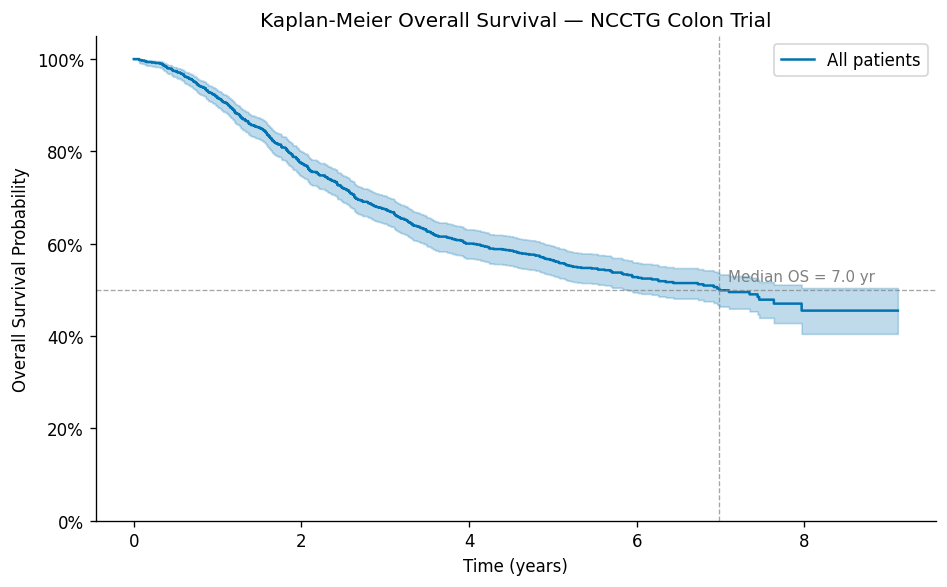

Median overall survival: 6.99 years


In [5]:
# KaplanMeierFitter is the lifelines class that estimates and stores the survival function.
# Calling it with () creates a blank fitter object ready to receive data.
kmf = KaplanMeierFitter()

# .fit() does the actual calculation. It takes:
#   durations: time to event or censoring for each patient
#   event_observed: 1 if the event (death) occurred, 0 if the patient was censored
#   label: the string that will appear in the plot legend
kmf.fit(
    durations=os_df['time_years'],
    event_observed=os_df['event'],
    label='All patients'
)

# plt.subplots() creates a Figure and an Axes object together.
# figsize=(8, 5) sets width=8 inches, height=5 inches.
# ax is what we pass to all subsequent plot calls to put everything on the same chart.
fig, ax = plt.subplots(figsize=(8, 5))

# .plot_survival_function() draws the step-down KM curve onto the axes.
# ci_show=True draws the shaded 95% confidence interval band (Greenwood formula).
# Wider shading means fewer patients still at risk, so the estimate is less certain.
kmf.plot_survival_function(ax=ax, ci_show=True)

# .median_survival_time_ is a stored attribute (lifelines convention: trailing underscore
# means it was computed during .fit()). It is the time at which survival probability = 0.5.
median_os = kmf.median_survival_time_

# Draw a crosshair at the median: horizontal line at 50%, vertical line at median time.
# alpha=0.7 makes the lines slightly transparent so they do not overpower the curve.
ax.axhline(0.5, color='gray', linestyle='--', linewidth=0.8, alpha=0.7)
ax.axvline(median_os, color='gray', linestyle='--', linewidth=0.8, alpha=0.7)

# ax.text() places a label at (x, y) in data space.
# The +0.1 offset shifts the label slightly right of the vertical line to avoid overlap.
ax.text(median_os + 0.1, 0.52, f'Median OS = {median_os:.1f} yr', fontsize=9, color='gray')

ax.set_xlabel('Time (years)')
ax.set_ylabel('Overall Survival Probability')
ax.set_title('Kaplan-Meier Overall Survival — NCCTG Colon Trial')
ax.set_ylim(0, 1.05)

# PercentFormatter(xmax=1) tells matplotlib the y values are proportions (0 to 1)
# and to display them as percentages (0% to 100%) on the axis tick labels.
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))

# tight_layout() automatically adjusts spacing so axis labels are not clipped.
plt.tight_layout()
plt.savefig('assets/km_overall.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Median overall survival: {median_os:.2f} years")


---
## 4. KM by Treatment Arm

This is the core question of the trial: does Lev+5FU improve survival over observation?

We plot three KM curves on the same axes and use the **log-rank test** to determine whether  
the differences are statistically significant (H₀: all survival curves are identical).

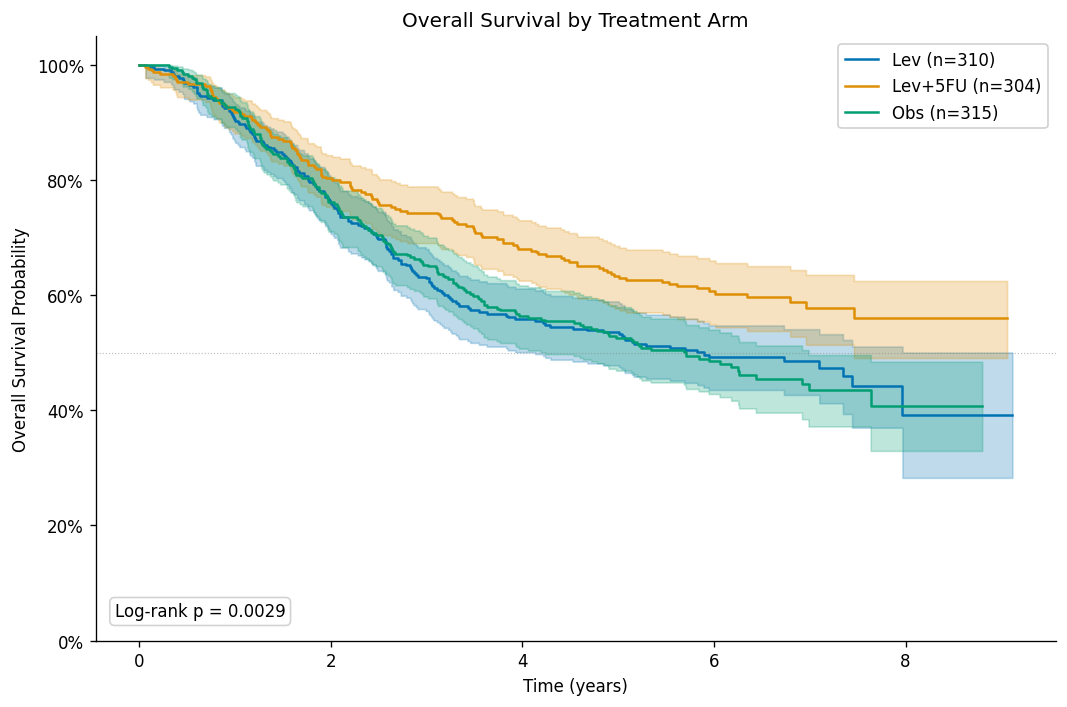

Log-rank test p-value: 0.002904
Test statistic: 11.683


In [6]:
# .unique() returns an array of the distinct values in the column, no duplicates.
treatment_groups = os_df['treatment'].unique()

# Generate one color per group from the colorblind-safe palette.
# n_colors= ensures we get exactly as many colors as there are groups.
colors = sns.color_palette('colorblind', n_colors=len(treatment_groups))

fig, ax = plt.subplots(figsize=(9, 6))

# Loop over each treatment arm and fit + plot a separate KM curve.
# zip() pairs each group label with its assigned color so they stay matched.
# sorted() puts the arms in alphabetical order: Lev, Lev+5FU, Obs.
for (group, color) in zip(sorted(treatment_groups), colors):
    # Boolean mask: True for rows in this treatment arm, False for all others.
    mask = os_df['treatment'] == group

    kmf_g = KaplanMeierFitter()

    # .loc[mask, column] selects only the rows where mask is True.
    # This is how we pass only the current group's data into the fitter.
    kmf_g.fit(
        durations=os_df.loc[mask, 'time_years'],
        event_observed=os_df.loc[mask, 'event'],
        label=f'{group} (n={mask.sum()})',
    )
    kmf_g.plot_survival_function(ax=ax, ci_show=True, color=color)

# The multivariate log-rank test asks: are all three survival curves simultaneously equal?
# H0: all groups have the same underlying survival function.
# A significant p-value means at least one group differs, but does not say which ones.
lr = multivariate_logrank_test(
    event_durations=os_df['time_years'],
    groups=os_df['treatment'],
    event_observed=os_df['event'],
)

ax.set_xlabel('Time (years)')
ax.set_ylabel('Overall Survival Probability')
ax.set_title('Overall Survival by Treatment Arm')
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.axhline(0.5, color='gray', linestyle=':', linewidth=0.7, alpha=0.5)

# transform=ax.transAxes means (0.02, 0.04) are fractions of the plot area, not data values.
# This keeps the annotation in the same corner regardless of the axis scale.
ax.text(0.02, 0.04, f'Log-rank p = {lr.p_value:.4f}', transform=ax.transAxes, fontsize=10,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='lightgray'))
ax.legend(loc='upper right', framealpha=0.9)

plt.tight_layout()
plt.savefig('assets/km_by_treatment.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Log-rank test p-value: {lr.p_value:.6f}")
print(f"Test statistic: {lr.test_statistic:.3f}")


---
## 5. KM by Nodal Burden (Lymph Node Groups)

Lymph node involvement is the strongest prognostic factor in stage III CRC.  
We bin `nodes` into clinically meaningful groups that mirror AJCC staging language:
- N1: 1–3 positive nodes
- N2a: 4–6 nodes
- N2b: 7+ nodes

In [7]:
# pd.cut() bins a continuous variable into labeled categories.
# bins= defines the boundary edges of each bin as a list. Each value falls in (left, right],
# meaning the left edge is excluded and the right edge is included.
# We use -1 as the first edge so that 0 nodes is captured in the first bin (nodes > -1 and <= 0).
# labels= assigns a name to each interval in the same order as the bin edges.
os_df['n_stage'] = pd.cut(
    os_df['nodes'],
    bins=[-1, 0, 3, 6, 100],
    labels=['N0 (0 nodes)', 'N1 (1-3)', 'N2a (4-6)', 'N2b (7+)']
)

# value_counts() counts patients per bin. .sort_index() reorders from N0 to N2b
# rather than by count, so the output matches clinical staging order.
print(os_df['n_stage'].value_counts().sort_index())


n_stage
N0 (0 nodes)      2
N1 (1–3)        593
N2a (4–6)       173
N2b (7+)        143
Name: count, dtype: int64


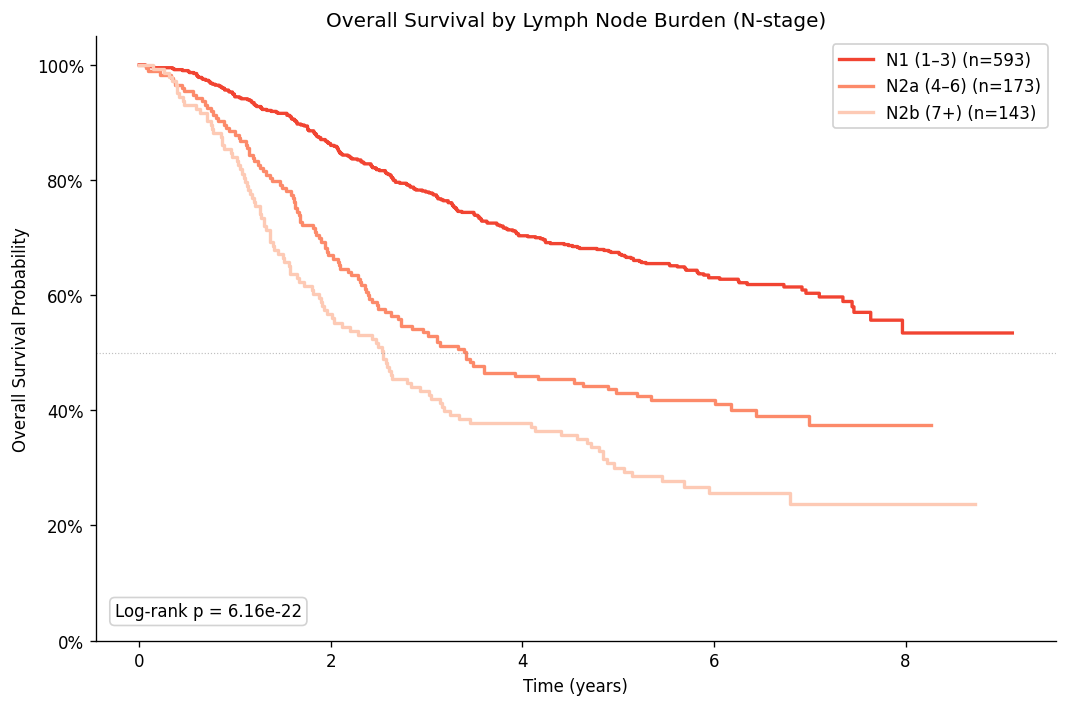

Log-rank p (node burden): 6.16e-22


In [8]:
# .cat.categories returns the ordered list of category labels from a Categorical column.
# This preserves the N0 < N1 < N2a < N2b ordering rather than resorting alphabetically.
n_groups = os_df['n_stage'].cat.categories

# 'Reds_r' is a sequential red colormap. The _r suffix reverses it so the lightest shade
# maps to N0 (best prognosis) and the darkest maps to N2b (worst prognosis).
colors = sns.color_palette('Reds_r', n_colors=len(n_groups))

fig, ax = plt.subplots(figsize=(9, 6))

for (group, color) in zip(n_groups, colors):
    mask = os_df['n_stage'] == group
    # Skip any bin with fewer than 5 patients. KM estimates are unreliable with tiny groups
    # because each single death causes an outsized step down in the curve.
    if mask.sum() < 5:
        continue
    kmf_g = KaplanMeierFitter()
    kmf_g.fit(
        durations=os_df.loc[mask, 'time_years'],
        event_observed=os_df.loc[mask, 'event'],
        label=f'{group} (n={mask.sum()})',
    )
    # ci_show=False omits the confidence bands. With 4 overlapping curves the shading
    # becomes visually cluttered, so linewidth=2 makes the lines more distinct instead.
    kmf_g.plot_survival_function(ax=ax, ci_show=False, color=color, linewidth=2)

lr_nodes = multivariate_logrank_test(
    event_durations=os_df['time_years'],
    groups=os_df['n_stage'],
    event_observed=os_df['event'],
)

ax.set_xlabel('Time (years)')
ax.set_ylabel('Overall Survival Probability')
ax.set_title('Overall Survival by Lymph Node Burden (N-stage)')
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.axhline(0.5, color='gray', linestyle=':', linewidth=0.7, alpha=0.5)

# :.2e formats the p-value in scientific notation with 2 decimal places (e.g. 4.71e-08).
# Used here because the node burden p-value is extremely small and would show as
# 0.0000 with a fixed-decimal format spec.
ax.text(0.02, 0.04, f'Log-rank p = {lr_nodes.p_value:.2e}', transform=ax.transAxes, fontsize=10,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='lightgray'))
ax.legend(loc='upper right', framealpha=0.9)

plt.tight_layout()
plt.savefig('assets/km_by_nodes.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Log-rank p (node burden): {lr_nodes.p_value:.2e}")


---
## 6. KM by Tumor Differentiation Grade

Tumor differentiation (histologic grade) correlates with aggressiveness.  
- Grade 1 (well differentiated) — cells look most like normal colon cells, slowest growing  
- Grade 2 (moderately differentiated) — most common  
- Grade 3 (poorly differentiated) — most aggressive, worst prognosis

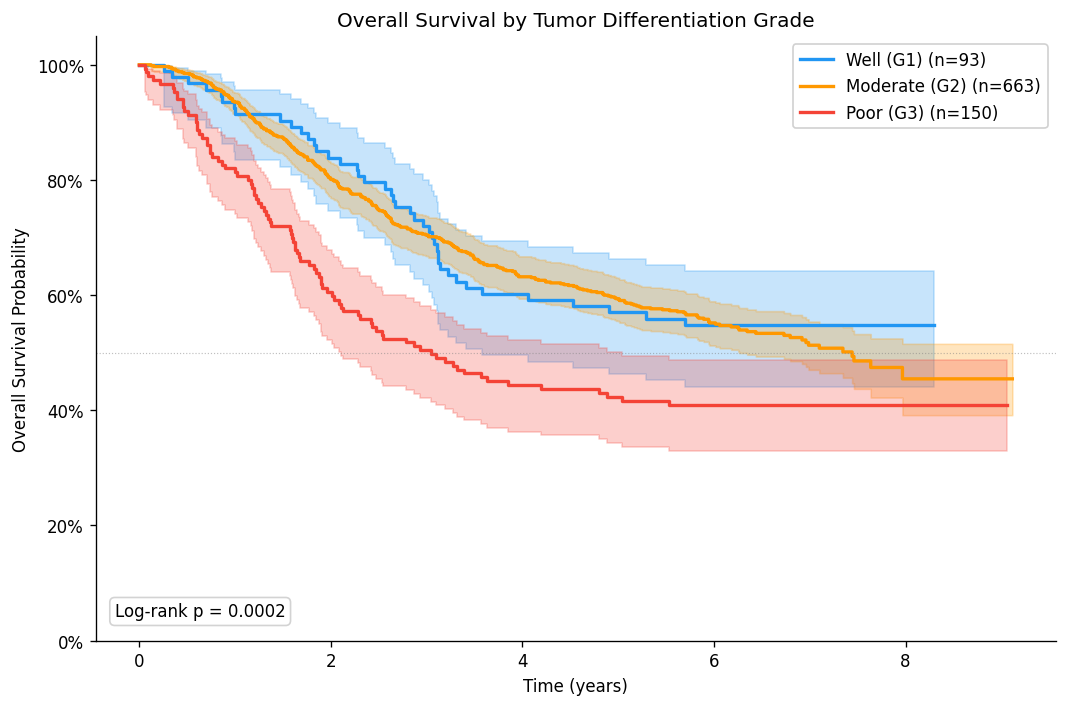

Log-rank p (tumor grade): 0.0002


In [9]:
# 'differ' stores tumor grade as integers (1, 2, 3).
# .map() replaces each value with its label from the dictionary.
# This converts numeric codes to readable strings for the plot legend.
grade_map = {1: 'Well (G1)', 2: 'Moderate (G2)', 3: 'Poor (G3)'}
os_df['grade'] = os_df['differ'].map(grade_map)

fig, ax = plt.subplots(figsize=(9, 6))

# Hex color codes give precise control: blue for best prognosis, orange for middle, red for worst.
# This uses traffic-light intuition so the visual hierarchy matches clinical meaning.
colors = ['#2196F3', '#FF9800', '#F44336']

for (grade_label, color) in zip(['Well (G1)', 'Moderate (G2)', 'Poor (G3)'], colors):
    mask = os_df['grade'] == grade_label
    if mask.sum() < 5:
        continue
    kmf_g = KaplanMeierFitter()
    kmf_g.fit(
        durations=os_df.loc[mask, 'time_years'],
        event_observed=os_df.loc[mask, 'event'],
        label=f'{grade_label} (n={mask.sum()})',
    )
    kmf_g.plot_survival_function(ax=ax, ci_show=True, color=color, linewidth=2)

# dropna(subset=['grade']) removes rows where grade is NaN (patients whose differentiation
# was not recorded). We must drop them before the log-rank test or it will error.
lr_grade = multivariate_logrank_test(
    event_durations=os_df.dropna(subset=['grade'])['time_years'],
    groups=os_df.dropna(subset=['grade'])['grade'],
    event_observed=os_df.dropna(subset=['grade'])['event'],
)

ax.set_xlabel('Time (years)')
ax.set_ylabel('Overall Survival Probability')
ax.set_title('Overall Survival by Tumor Differentiation Grade')
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.axhline(0.5, color='gray', linestyle=':', linewidth=0.7, alpha=0.5)
ax.text(0.02, 0.04, f'Log-rank p = {lr_grade.p_value:.4f}', transform=ax.transAxes, fontsize=10,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='lightgray'))
ax.legend(loc='upper right', framealpha=0.9)

plt.tight_layout()
plt.savefig('assets/km_by_grade.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Log-rank p (tumor grade): {lr_grade.p_value:.4f}")


---
## 7. Cox Proportional Hazards Regression

KM curves show one variable at a time. Cox regression shows **independent effects**  
after controlling for all other variables simultaneously.

### The hazard ratio (HR) — what it means

Cox regression outputs a **hazard ratio** for each predictor:
- **HR = 1.0** → no effect on survival
- **HR > 1.0** → higher hazard (worse survival). HR = 2.0 means "twice the risk of death at any moment"
- **HR < 1.0** → lower hazard (better survival). HR = 0.5 means "half the risk" = protective

### The proportional hazards assumption

Cox PH assumes the **hazard ratio between groups is constant over time** (the curves never cross).  
If two groups' survival curves cross, the proportional hazards assumption is violated and Cox results  
are unreliable for that variable. We check this with Schoenfeld residuals after fitting.

In [10]:
# Cox PH requires a DataFrame where every column is numeric.
# We select only the variables we want in the model and make a copy
# so changes here do not affect os_df.
cox_df = os_df[['time_years', 'event', 'age', 'sex', 'nodes',
                 'obstruct', 'differ', 'extent', 'treatment']].copy()

# 'treatment' is a text column (Obs, Lev, Lev+5FU). Cox PH cannot handle text.
# pd.get_dummies() converts it to binary (0/1) columns, one per category.
# This is called one-hot encoding. drop_first=False keeps all three so we can
# manually choose which to drop as the reference category.
cox_df = pd.get_dummies(cox_df, columns=['treatment'], drop_first=False)

# We drop the reference category (Obs) manually.
# If we kept all three dummy columns, their values would always sum to 1 for every row.
# That is perfect multicollinearity and makes the model mathematically unsolvable.
# Dropping one means the remaining two are interpreted as effects relative to Obs.
if 'treatment_Obs' in cox_df.columns:
    cox_df = cox_df.drop(columns=['treatment_Obs'])

# Cox PH will error if any NaN is present.
# .dropna() removes any row that has at least one NaN in any column.
cox_df = cox_df.dropna()

# pd.get_dummies() can return boolean (True/False) columns depending on the pandas version.
# CoxPHFitter expects integers (0/1), so we convert any boolean columns explicitly.
bool_cols = cox_df.select_dtypes(include='bool').columns
cox_df[bool_cols] = cox_df[bool_cols].astype(int)

print(f"Model matrix shape: {cox_df.shape}")
print(f"Columns: {list(cox_df.columns)}")


Model matrix shape: (888, 10)
Columns: ['time_years', 'event', 'age', 'sex', 'nodes', 'obstruct', 'differ', 'extent', 'treatment_Lev', 'treatment_Lev+5FU']


In [11]:
# CoxPHFitter is the lifelines class for Cox proportional hazards regression.
# penalizer=0.1 adds a small L2 penalty (ridge regularization) to the log-likelihood.
# This slightly shrinks coefficient estimates toward zero, which improves numerical
# stability when predictors are correlated with each other (like nodes and extent often are).
cph = CoxPHFitter(penalizer=0.1)

# .fit() runs maximum likelihood estimation to find the best-fitting hazard ratios.
#   duration_col: the column containing time to event or censoring
#   event_col: the column containing the 0/1 event indicator
#   show_progress=False suppresses the iteration log that prints during fitting
cph.fit(
    df=cox_df,
    duration_col='time_years',
    event_col='event',
    show_progress=False,
)

# .print_summary() displays the full regression table: one row per predictor showing
# the hazard ratio (exp(coef)), 95% CI, z-score, and p-value.
# decimals=3 controls how many decimal places appear in the table.
cph.print_summary(decimals=3, model='CRC Colon Trial — Cox PH')


model,lifelines.CoxPHFitter
duration col,'time_years'
event col,'event'
penalizer,0.1
l1 ratio,0.0
baseline estimation,breslow
number of observations,888
number of events observed,430
partial log-likelihood,-2720.344
time fit was run,2026-04-08 23:50:39 UTC
model,CRC Colon Trial — Cox PH


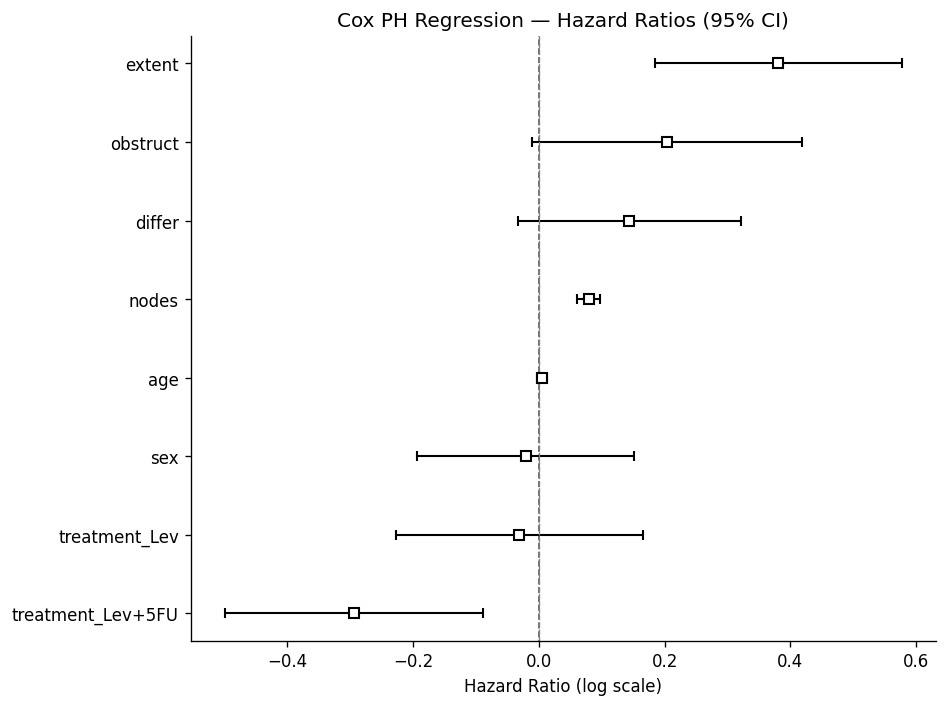

In [12]:
# A forest plot shows each predictor's hazard ratio as a dot with a horizontal line
# extending to its 95% confidence interval on both sides.
# Variables whose CI line crosses HR=1.0 are not statistically significant.
fig, ax = plt.subplots(figsize=(8, 6))

# cph.plot() is a built-in lifelines method that generates the forest plot automatically
# from the fitted model. It plots on a log scale internally, then labels the ticks
# with the actual HR values.
cph.plot(ax=ax)

ax.set_title('Cox PH Regression — Hazard Ratios (95% CI)')
ax.set_xlabel('Hazard Ratio (log scale)')

# The x-axis is on a log scale. log(HR=1) = 0, so a vertical line at x=0 is the
# 'no effect' reference. Variables to the right increase hazard (worse survival).
ax.axvline(0, color='gray', linestyle='--', linewidth=0.8)

plt.tight_layout()
plt.savefig('assets/cox_forest.png', dpi=150, bbox_inches='tight')
plt.show()



   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'obstruct' failed the non-proportional test: p-value is 0.0076.

   Advice: with so few unique values (only 2), you can include `strata=['obstruct', ...]` in the
call in `.fit`. See documentation in link [E] below.

   Bootstrapping lowess lines. May take a moment...


2. Variable 'differ' failed the non-proportional test: p-value is 0.0008.

   Advice: with so few unique values (only 3), you can include `strata=['differ', ...]` in the call
in `.fit`. See documentation in link [E] below.

   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


---
[A]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html
[B]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Bin-variable-and-stratify-on-it
[C]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20h

[[<Axes: xlabel='rank-transformed time\n(p=0.2564)'>,
  <Axes: xlabel='km-transformed time\n(p=0.2662)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.7304)'>,
  <Axes: xlabel='km-transformed time\n(p=0.6749)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.7272)'>,
  <Axes: xlabel='km-transformed time\n(p=0.7444)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.0076)'>,
  <Axes: xlabel='km-transformed time\n(p=0.0099)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.0008)'>,
  <Axes: xlabel='km-transformed time\n(p=0.0009)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.1932)'>,
  <Axes: xlabel='km-transformed time\n(p=0.1949)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.1539)'>,
  <Axes: xlabel='km-transformed time\n(p=0.1638)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.2750)'>,
  <Axes: xlabel='km-transformed time\n(p=0.2763)'>]]

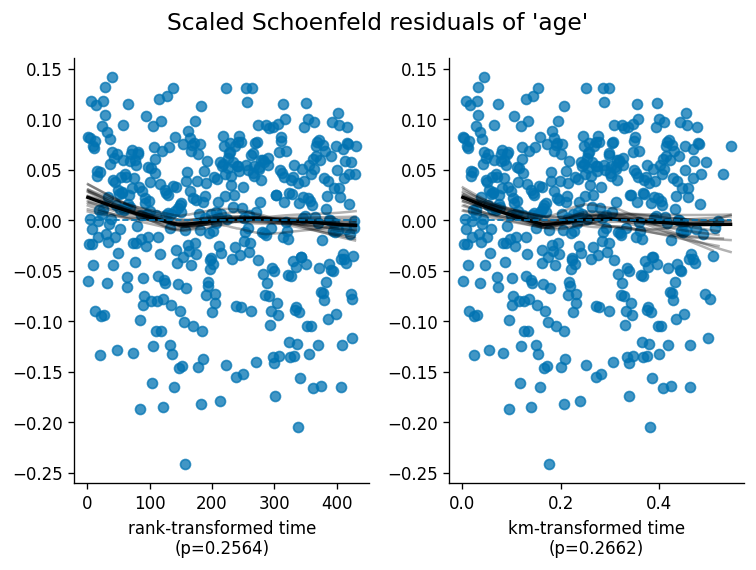

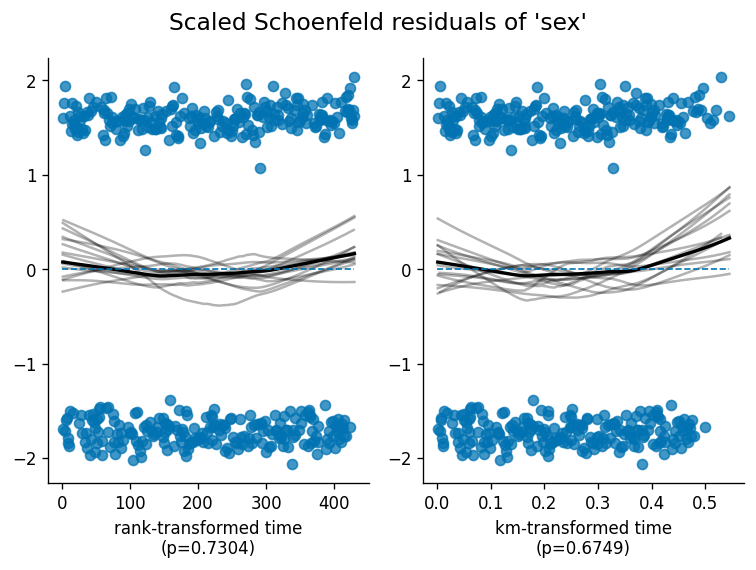

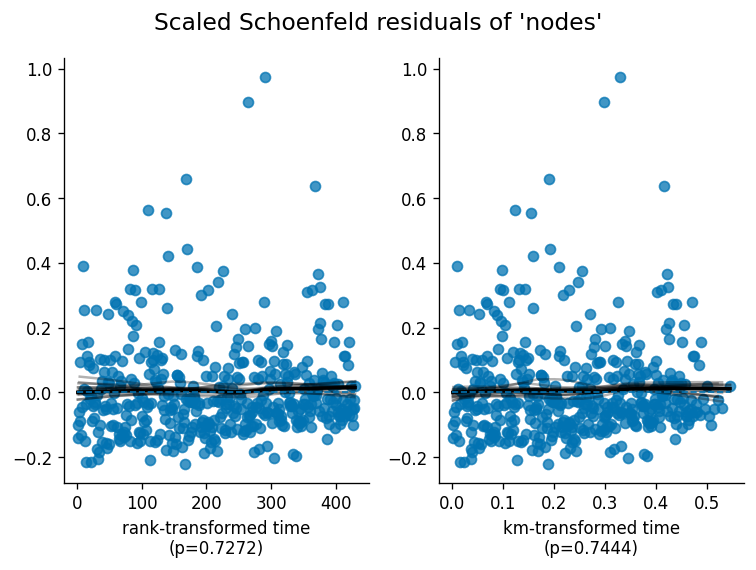

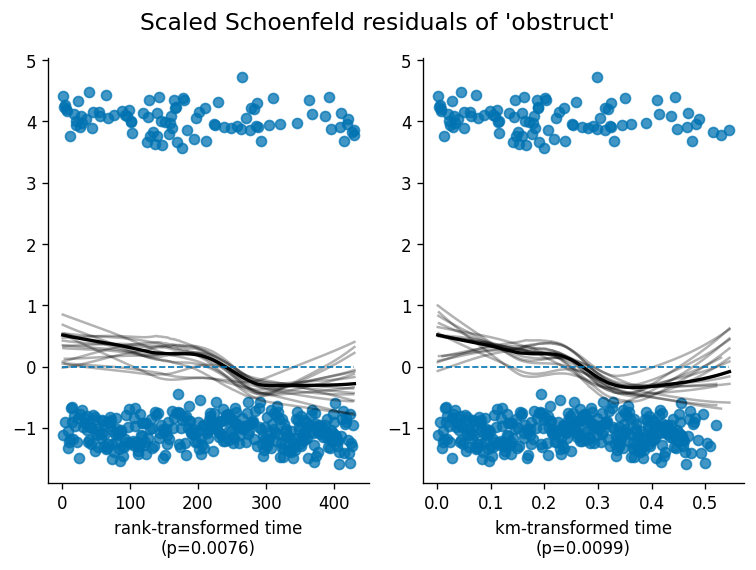

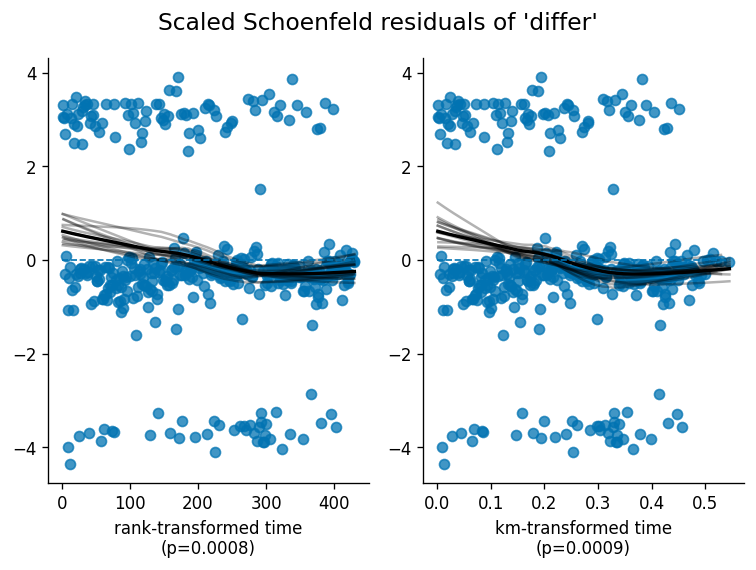

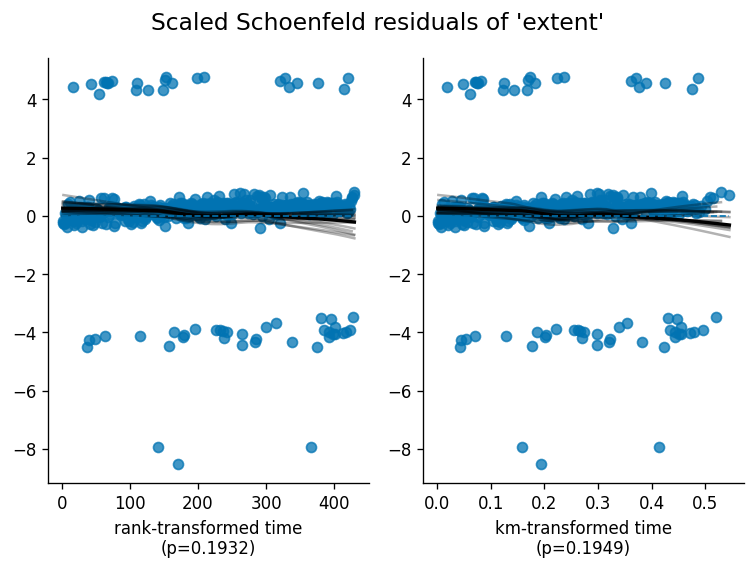

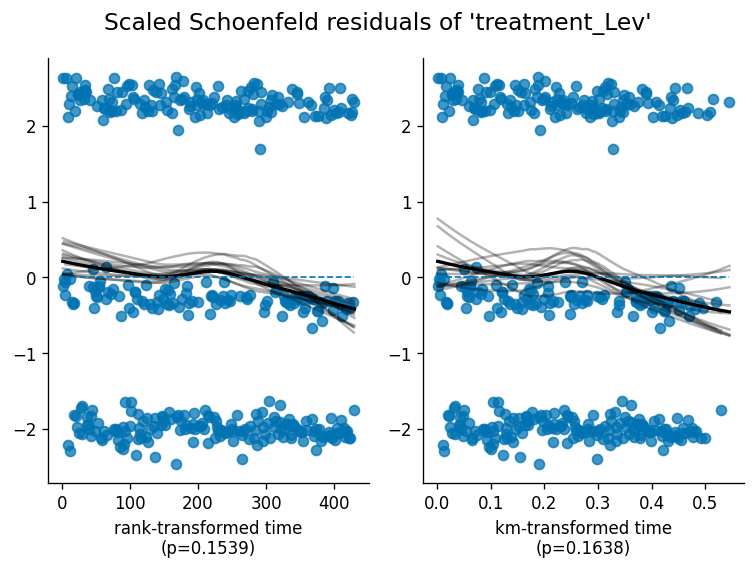

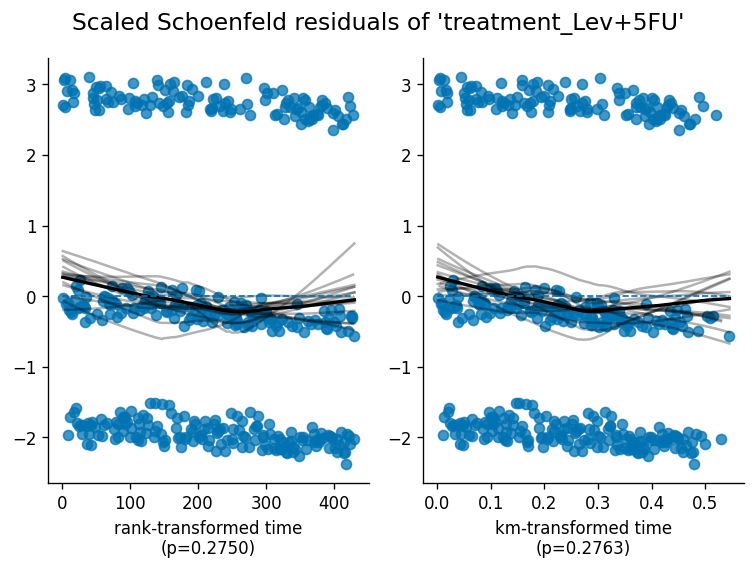

In [13]:
# The proportional hazards assumption requires that each predictor's effect on survival
# is constant over time. If treatment matters early but fades after 5 years, for example,
# PH is violated for that variable and the Cox HR becomes an unreliable average.
#
# .check_assumptions() tests this using Schoenfeld residuals.
# For each predictor: p < 0.05 means the PH assumption is violated for that variable.
# The global test checks whether any variable violates it across the whole model.
# show_plots=True draws residual-over-time plots so you can see whether the effect
# drifts upward, downward, or stays flat as time progresses.
cph.check_assumptions(cox_df, p_value_threshold=0.05, show_plots=True)


---
## 8. Univariate Cox Screen

Before the multivariable model, it's standard to run each predictor independently.  
Variables with p < 0.10 in univariate analysis are typically included in the multivariable model.  
This helps justify model variable selection.

In [14]:
# Build a list of predictor column names by excluding the two outcome columns.
# List comprehension: for each column name c in cox_df.columns, include it
# only if it is not 'time_years' and not 'event'.
predictors = [c for c in cox_df.columns if c not in ['time_years', 'event']]
rows = []

# Fit a separate one-variable Cox model for each predictor independently.
# This is a univariate screen: it shows each variable's raw association with survival
# before adjusting for anything else. Variables with p < 0.10 here are the standard
# threshold for inclusion in the multivariable model.
for var in predictors:
    # Select only the three needed columns and drop rows missing this variable.
    uni_df = cox_df[['time_years', 'event', var]].dropna()

    uni_cph = CoxPHFitter(penalizer=0.1)
    uni_cph.fit(uni_df, duration_col='time_years', event_col='event', show_progress=False)

    # .summary is a DataFrame containing all fitted statistics for this model.
    # .values[0] pulls the first (and only) row's value as a plain scalar number.
    summary = uni_cph.summary
    rows.append({
        'Variable': var,
        'HR': summary['exp(coef)'].values[0],
        'HR_lower': summary['exp(coef) lower 95%'].values[0],
        'HR_upper': summary['exp(coef) upper 95%'].values[0],
        'p': summary['p'].values[0],
    })

# Convert the list of dictionaries into a DataFrame, sorted ascending by p-value
# so the strongest associations appear at the top.
uni_results = pd.DataFrame(rows).sort_values('p')

# Build the HR (95% CI) string column. This is the clinical report string format.
# .apply() runs the lambda function on each row (axis=1 means row by row, not column by column).
# Each row becomes a formatted string like '2.14 (1.67-2.73)'.
uni_results['HR_CI'] = uni_results.apply(
    lambda r: f"{r['HR']:.2f} ({r['HR_lower']:.2f}-{r['HR_upper']:.2f})", axis=1
)

# Significance stars as a quick visual cue. The nested ternary reads:
# if p<0.001 return ***, else if p<0.01 return **, else if p<0.05 return *, else blank.
uni_results['sig'] = uni_results['p'].apply(
    lambda p: '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else ''))
)

display(uni_results[['Variable', 'HR_CI', 'p', 'sig']].to_string(index=False))


'         Variable            HR_CI            p sig\n            nodes 1.09 (1.07–1.11) 4.300080e-20 ***\n           extent 1.56 (1.29–1.90) 6.801705e-06 ***\ntreatment_Lev+5FU 0.75 (0.62–0.91) 2.941277e-03  **\n           differ 1.27 (1.07–1.51) 6.859895e-03  **\n         obstruct 1.23 (1.00–1.52) 5.521215e-02    \n    treatment_Lev 1.10 (0.92–1.32) 3.037978e-01    \n              age 1.00 (1.00–1.01) 5.312134e-01    \n              sex 0.99 (0.84–1.18) 9.412837e-01    '

---
## 9. Predicted Survival Curves from Cox Model

Unlike KM curves (which are purely empirical), Cox-predicted curves let us estimate survival  
for hypothetical patient profiles — e.g., "what is predicted OS for a 65-year-old with 6 positive  
nodes on Lev+5FU vs observation?"

This is the clinical utility of Cox regression beyond just reporting HRs.

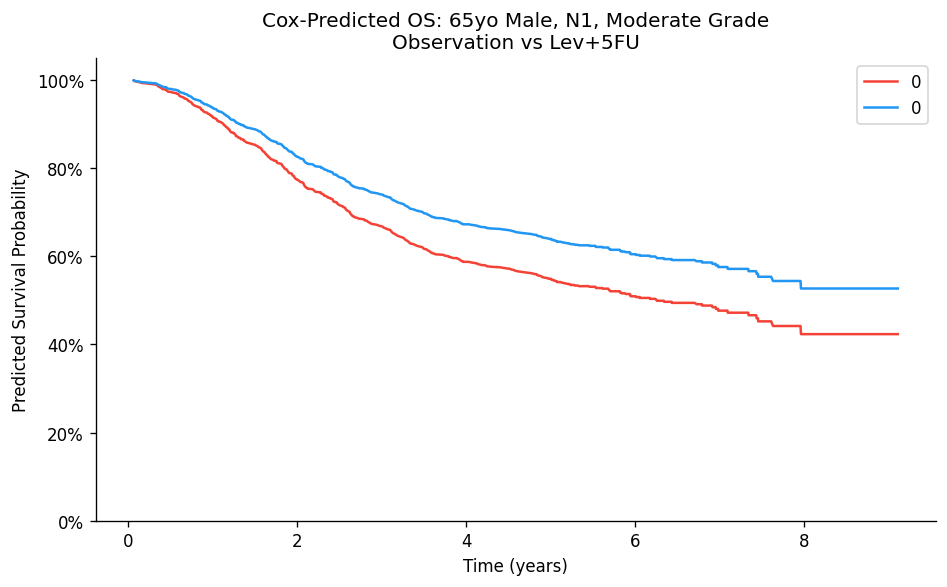

In [15]:
# Build a baseline patient profile as a dictionary.
# Dictionary comprehension: for each column in the model matrix (excluding outcomes),
# start every value at 0. Then .update() overwrites specific values with the patient profile.
base = {col: 0 for col in cox_df.columns if col not in ['time_years', 'event']}
base.update({'age': 65, 'sex': 1, 'nodes': 3, 'obstruct': 0, 'differ': 2, 'extent': 3})

# pd.DataFrame([base]) wraps the dictionary in a list to make a single-row DataFrame.
# .predict_survival_function() requires a DataFrame, not a plain dictionary.
profile_obs = pd.DataFrame([base])

# Patient B gets the same base profile but with the Lev+5FU dummy column set to 1.
# {**base, **{'treatment_Lev+5FU': 1}} merges two dictionaries together.
# The ** operator unpacks a dictionary into its key-value pairs.
# When two dictionaries are merged this way, the second one's values override the first
# for any shared keys, so treatment_Lev+5FU is overwritten from 0 to 1.
profile_lev5fu = pd.DataFrame([{**base, **{'treatment_Lev+5FU': 1}}]) \
    if 'treatment_Lev+5FU' in cox_df.columns else pd.DataFrame([base])

fig, ax = plt.subplots(figsize=(8, 5))

# .predict_survival_function() uses the fitted Cox model to generate a survival curve
# for a hypothetical patient profile. This is the key advantage over KM curves:
# you can predict for any patient profile, not just the groups that exist in the data.
cph.predict_survival_function(profile_obs).plot(ax=ax, label='Obs (no adjuvant)', color='#F44336')
cph.predict_survival_function(profile_lev5fu).plot(ax=ax, label='Lev+5FU', color='#2196F3')

ax.set_xlabel('Time (years)')
ax.set_ylabel('Predicted Survival Probability')
ax.set_title('Cox-Predicted OS: 65yo Male, N1, Moderate Grade\nObservation vs Lev+5FU')
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.legend()

plt.tight_layout()
plt.savefig('assets/cox_predicted.png', dpi=150, bbox_inches='tight')
plt.show()


---
## 10. Summary Table — Cohort Characteristics

Standard "Table 1" for a clinical paper — patient characteristics by treatment arm.

In [16]:
# summarize_group() is a custom function that takes a subset of os_df (one treatment arm)
# and returns a pandas Series where the index is the row label and the value is a
# formatted string ready to appear as a cell in a publication-style table.
# pd.Series({...}) creates a Series from a dictionary: keys become the index, values become the data.
def summarize_group(df):
    return pd.Series({
        'N': len(df),
        # 'count (percent%)' format. .sum() counts deaths (1s), .mean()*100 gives the percentage.
        'Deaths, n (%)': f"{df['event'].sum()} ({df['event'].mean()*100:.1f}%)",
        # 'median (Q1-Q3)' format. .quantile(0.25) and .quantile(0.75) are the IQR boundaries.
        'Age, median (IQR)': f"{df['age'].median():.0f} ({df['age'].quantile(0.25):.0f}-{df['age'].quantile(0.75):.0f})",
        'Male sex, n (%)': f"{df['sex'].sum()} ({df['sex'].mean()*100:.1f}%)",
        'Pos. nodes, median (IQR)': f"{df['nodes'].median():.0f} ({df['nodes'].quantile(0.25):.0f}-{df['nodes'].quantile(0.75):.0f})",
        'Obstruction, n (%)': f"{df['obstruct'].sum()} ({df['obstruct'].mean()*100:.1f}%)",
        # (df['differ']==3) creates a boolean Series: True where grade is poor (3).
        # .sum() counts the Trues, .mean()*100 gives the percentage with poor differentiation.
        'Poor differentiation, n (%)': f"{(df['differ']==3).sum()} ({(df['differ']==3).mean()*100:.1f}%)",
    })

# .groupby('treatment') splits os_df into three sub-DataFrames, one per treatment arm.
# .apply(summarize_group) runs our function on each sub-DataFrame and stacks the results.
# .T transposes the output so treatment arms are columns and characteristics are rows,
# which is the standard Table 1 orientation for a clinical paper.
table1 = os_df.groupby('treatment').apply(summarize_group).T
display(table1)


C:\Users\palla\AppData\Local\Temp\ipykernel_42620\1413601412.py:13: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  table1 = os_df.groupby('treatment').apply(summarize_group).T


treatment,Lev,Lev+5FU,Obs
N,310,304,315
"Deaths, n (%)",161 (51.9%),123 (40.5%),168 (53.3%)
"Age, median (IQR)",61 (53–69),62 (52–70),60 (53–68)
"Male sex, n (%)",177 (57.1%),141 (46.4%),166 (52.7%)
"Pos. nodes, median (IQR)",2 (1–5),2 (1–4),2 (1–5)
"Obstruction, n (%)",63 (20.3%),54 (17.8%),63 (20.0%)
"Poor differentiation, n (%)",44 (14.2%),54 (17.8%),52 (16.5%)


---
## Phase 2: Loading Real SEER Data

Once your SEER Data Use Agreement is approved:

### Step 1 — Apply for SEER access
Go to: https://seer.cancer.gov/data/access.html  
Fill out the DUA form. Approval is typically same-day (automated).

### Step 2 — Download SEER*Stat
Install SEER*Stat (Windows only, or Wine on Mac/Linux).  
Use it to export a CRC cohort as a flat `.txt` file.

**Recommended export variables:**
- Patient ID, age at diagnosis, sex, race
- Primary site (colon vs rectum)
- Histology (adenocarcinoma, mucinous, signet ring)
- AJCC stage (I, II, III, IV)
- MSI status (available from 2018+ in SEER)
- Cause-specific survival months
- Vital status (alive/dead)
- Year of diagnosis (1990–2021)

### Step 3 — Replace the load cell below

```python
# ── Phase 2: Real SEER flat file ──────────────────────────────────────────────
import seer_parser  # pip install seerpy or parse manually

# SEER exports are fixed-width or CSV depending on export settings
# CSV export is easier — select CSV in SEER*Stat export options
seer_raw = pd.read_csv('data/seer_crc_export.csv', low_memory=False)

# Rename SEER column names to match this notebook's variable names
# SEER uses different column headers depending on the version
seer_raw = seer_raw.rename(columns={
    'Survival months':       'time',
    'Vital status recode':   'status',  # 'Alive' or 'Dead'
    'Age recode with <1 year olds': 'age',
    'Sex':                   'sex',
    'AJCC Stage Group':      'stage',
})

# Convert months to years
seer_raw['time_years'] = seer_raw['time'] / 12
seer_raw['event'] = (seer_raw['status'] == 'Dead').astype(int)
```

After that, all cells below (KM curves, Cox regression) work without modification  
— just substitute `seer_raw` for `os_df`.

### Why SEER over the trial dataset?
- **Scale**: 100,000+ CRC patients vs 929 in the trial
- **Real-world**: community practice, not just academic trial centers
- **MSI status**: available from 2018 (not in the trial dataset)
- **Subsite**: colon vs rectum, right-sided vs left-sided (prognostically different)
- **Racial disparities**: large enough N to stratify by race/ethnicity

---
## Interpretation Guide

### Reading this notebook's outputs

| Output | What to report |
|--------|---------------|
| KM curve | Median survival time + 95% CI for each group |
| Log-rank p | Statistical significance of survival difference (threshold: p < 0.05) |
| Cox HR | "Patients with X had HR = Y (95% CI: a–b), p = Z, after adjusting for..." |
| Forest plot | Which variables significantly affect survival after multivariable adjustment |
| PH test | Whether Cox assumptions hold — if violated, consider time-varying coefficients |

### Connection to the Colo project

When the Colo agents discuss CRC survival outcomes, they reference published trial data.  
This SEER analysis provides the real-world empirical grounding:
- Trial data shows efficacy under controlled conditions
- SEER shows effectiveness in the actual patient population
- The gap between the two is clinically meaningful

The planned **Epidemiology Agent C** (see Colo DESIGN_NOTES.md) would run this analysis  
dynamically and return population-level survival statistics to ground the agent debate.